### **Regresión:** predecir el número total de bicicletas alquiladas
**Justificación del valor analítico:**
<P>  Ayuda a la planificación de stock, mantenimiento y personal en una empresa de bicicletas compartidas.</P>
​

**Permite analizar cómo influyen clima, hora, día y estación en la demanda.**
<P> MICHAEL VENTURA</P>
<P>FUENTE: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset</P>

#### **Planteamiento claro del problema**

<P>Predecir el número de bicicletas alquiladas (cnt_y) en un horario específico usando variables de tiempo, clima y estacionalidad.</P>


####Hipótesis interesantes:
<P>La demanda aumenta en horas pico (mañana y tarde).</P>
<P>El clima bueno (temp alta, hum baja, viento bajo) incrementa la demanda.</P>​

### PREPARACION DE AMBIENTE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Ridge

from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, r2_score



### CARGA DE DATASET

In [2]:
day_df = pd.read_csv('day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [4]:
hour_df = pd.read_csv('hour.csv')
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


#### UNIFICACION DE DATASETS

In [6]:
bike_df = pd.merge(day_df, hour_df, on='instant')
bike_df.head()

,instant,dteday_x,season_x,yr_x,mnth_x,holiday_x,weekday_x,workingday_x,weathersit_x,temp_x,...,weekday_y,workingday_y,weathersit_y,temp_y,atemp_y,hum_y,windspeed_y,casual_y,registered_y,cnt_y
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,...,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,...,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [7]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 32 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   instant       731 non-null    int64  
 1   dteday_x      731 non-null    object 
 2   season_x      731 non-null    int64  
 3   yr_x          731 non-null    int64  
 4   mnth_x        731 non-null    int64  
 5   holiday_x     731 non-null    int64  
 6   weekday_x     731 non-null    int64  
 7   workingday_x  731 non-null    int64  
 8   weathersit_x  731 non-null    int64  
 9   temp_x        731 non-null    float64
 10  atemp_x       731 non-null    float64
 11  hum_x         731 non-null    float64
 12  windspeed_x   731 non-null    float64
 13  casual_x      731 non-null    int64  
 14  registered_x  731 non-null    int64  
 15  cnt_x         731 non-null    int64  
 16  dteday_y      731 non-null    object 
 17  season_y      731 non-null    int64  
 18  yr_y          731 non-null    

### VALIDACION DE DATOS NULOS

In [ ]:
bike_df.isna().sum()

,0
instant,0
dteday_x,0
season_x,0
yr_x,0
mnth_x,0
holiday_x,0
weekday_x,0
workingday_x,0
weathersit_x,0
temp_x,0


### SELECCION DE VARIABLES

In [8]:
bike_X = bike_df[[
    "yr_y",          # 0 = 2011, 1 = 2012
    "mnth_y",        # 1–12
    "hr",            # 0–23
    "season_y",      # 1–4
    "weekday_y",     # 0–6
    "workingday_y",  # 0/1
    "weathersit_y",  # 1–4
    "temp_y",        # temperatura normalizada (0–1)
    "hum_y",         # humedad (0–1)
    "windspeed_y"    # viento (0–1)
]]
bike_y = bike_df["cnt_y"]     # número de bicicletas alquiladas

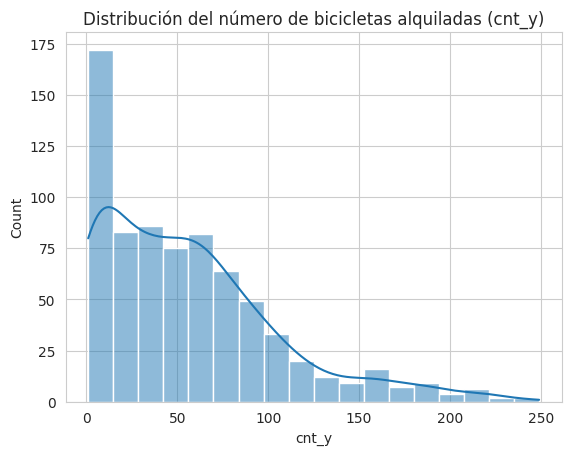

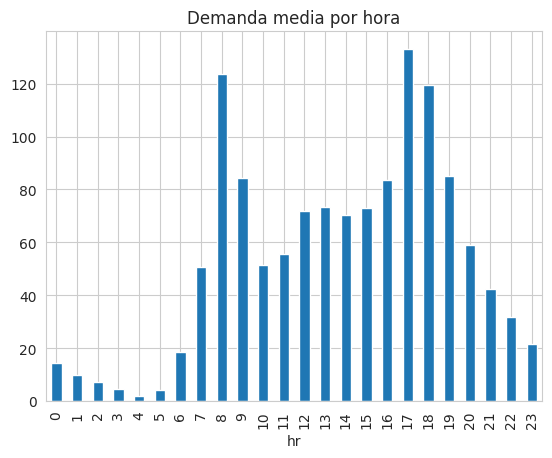

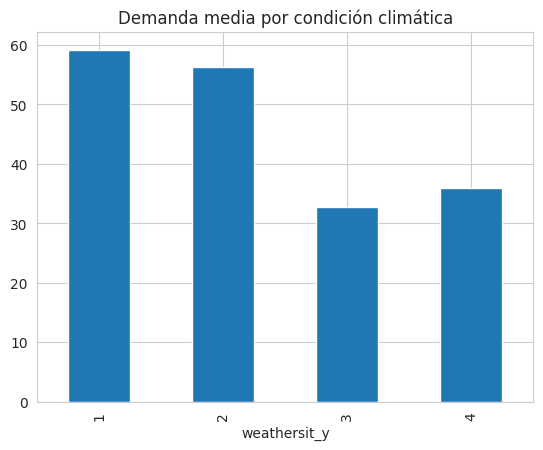

In [9]:
sns.set_style("whitegrid")

# 1. Distribución de cnt_y (objetivo)
sns.histplot(bike_y, kde=True)
plt.title("Distribución del número de bicicletas alquiladas (cnt_y)")
plt.show()

# 2. Media de cnt_y por hora
bike_df.groupby("hr")["cnt_y"].mean().plot(kind="bar")
plt.title("Demanda media por hora")
plt.show()

# 3. Demanda por clima y estación
bike_df.groupby("weathersit_y")["cnt_y"].mean().plot(kind="bar")
plt.title("Demanda media por condición climática")
plt.show()

### DETECCION DE OUTLIERS

In [10]:
Q1 = bike_y.quantile(0.25)
Q3 = bike_y.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

outliers = bike_y[(bike_y < lower) | (bike_y > upper)]
print("Outliers en cnt_y:", len(outliers))

Outliers en cnt_y: 26


### CLASIFICACION

In [11]:
X_cat = bike_X[["season_y", "weekday_y", "weathersit_y"]].astype("category")
X_cat = pd.get_dummies(X_cat, prefix=["season", "weekday", "weather"], drop_first=True)

X_num = bike_X[["yr_y", "mnth_y", "hr", "workingday_y", "temp_y", "hum_y", "windspeed_y"]]

X_clean = pd.concat([X_num, X_cat], axis=1)

### ESCALAMIENTO

In [12]:
scalar = StandardScaler()
X_scaled = X_clean.copy()
X_scaled[["yr_y", "mnth_y", "hr", "temp_y", "hum_y", "windspeed_y"]] = \
    scalar.fit_transform(X_clean[["yr_y", "mnth_y", "hr", "temp_y", "hum_y", "windspeed_y"]])

#### LIMPIEZA

In [13]:
X_clean["is_peak_hour"] = np.where(X_clean["hr"].isin([8,9,17,18]), 1, 0)


#### MODELADO

In [14]:

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, bike_y, test_size=0.2, random_state=42
)

In [15]:

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

Ridge()

In [16]:

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_leaf=4, min_samples_split=10,
                      n_estimators=200, n_jobs=-1, random_state=42)

### VALIDACION Y EVALUACION

In [17]:


models = [("Ridge", ridge), ("RandomForest", rf)]

for name, model in models:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    print(name, "R² (CV):", scores.mean(), "±", scores.std())

Ridge R² (CV): 0.2206229589140875 ± 0.0379949077365227
RandomForest R² (CV): 0.8672345650265326 ± 0.014749465280808954


Ridge MSE: 1679.4410769306262 RMSE: 40.98098433335424 R²: 0.3148828426407938


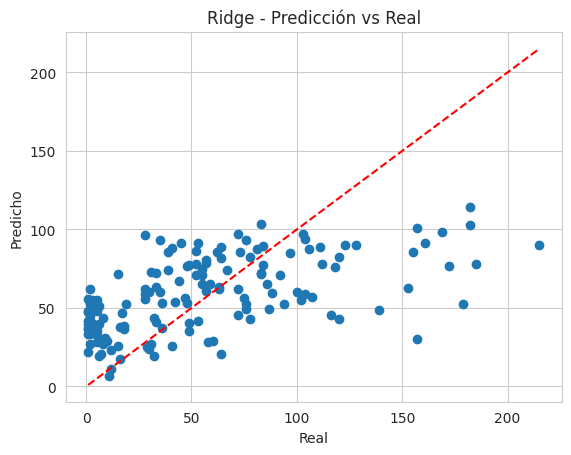

RandomForest MSE: 196.44309883679963 RMSE: 14.015816024648712 R²: 0.9198623046044139


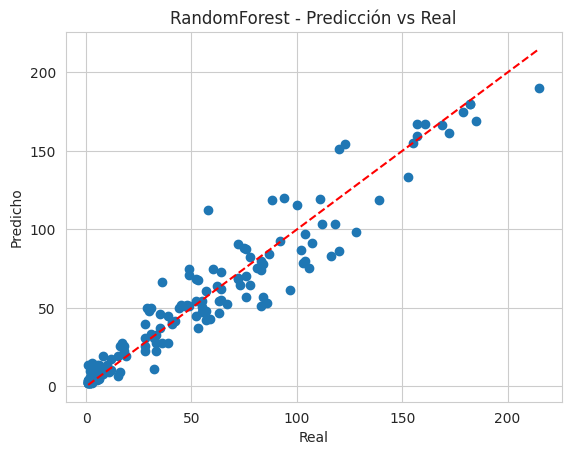

In [18]:
for name, model in models:
    y_pred = model.predict(X_test)
    mse  = mean_squared_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)
    rmse = np.sqrt(mse)

    print(name, "MSE:", mse, "RMSE:", rmse, "R²:", r2)

    # Gráfico de predicción vs real
    plt.figure()
    plt.scatter(y_test, y_pred)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    plt.xlabel("Real")
    plt.ylabel("Predicho")
    plt.title(f"{name} - Predicción vs Real")
    plt.show()